# ECHO — Investigation Notebook
**Entangled Minds: The Quantathon · Qubits Qrew, NED University**
**Investigator:** Amna Shahzad (Roll No. CT_24018, Section B, AI) · **Case report:** [`Case_Report.pdf`](Case_Report.pdf) (same repository)

> *"They told me entanglement could never carry a message. I proved them wrong. …Or did I? Find the flaw before they bury it with me." — Z*

| Module | Type | Depth reached | Result in one line |
|---|---|---|---|
| 01 The Gatekeeper | Mandatory | 🥇 Gold | X → always 1 · H → 50/50 · H·H → secretly always 0 · vault `101` |
| 02 The Honest Coin | Stretch | 🥇 Gold | The "random" seed is a loaded coin: P(1) = sin²(1.159/2) = **0.300** |
| 03 The Two Observers | Mandatory | 🥇 Gold + CHSH bonus | Agreement ≠ link · the X-basis test separates them · Bob's results never depend on Alice |
| 04 The Erased Measurement | Stretch | 🥇 Gold | Gates are always reversible; only a measurement erases, and only the first time |
| 05 The Damaged Message | Mandatory | 🥇 Gold | Her last word: **ECHO** · corrects 1 flip, notices 2 · a qubit can't be copied |
| 06 The Impossible Claim | Stretch (**declared**) | 🥇 Gold | Teleportation needs 2 classical bits; without them Bob holds exactly I/2, so nothing is faster than light |

**Declared stretch module: 06.** Modules 02 and 04 were also completed as extra evidence (the rules ask for *at least one* stretch module).

**Every module follows the same steps:** 🔮 Predict → 🛠 Build & run → 📊 Result → ✅ What it proves → 🔎 Clue for the case.

**To run:** *Runtime → Run all* (about 1–2 min on Colab). The random seeds are fixed, so every number reproduces exactly. All results come from the ideal (noise-free) `AerSimulator`.

### Setup — run first

In [1]:
# Installs Qiskit on Colab if it is missing (pinned versions → reproducible results)
import importlib.util
if any(importlib.util.find_spec(m) is None for m in ["qiskit", "qiskit_aer", "pylatexenc", "scipy"]):
    get_ipython().run_line_magic("pip", "install -q qiskit==2.6.0 qiskit-aer==0.18.0 pylatexenc matplotlib scipy")

import os
import numpy as np, matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, partial_trace, state_fidelity
from qiskit.visualization import plot_histogram
from scipy.stats import binomtest

sim = AerSimulator()
_rng = np.random.default_rng(2026)            # one master seed → the same numbers on every run

def run(circuit, shots=2000):
    """Run a circuit on the ideal simulator and return the measured counts."""
    seed = int(_rng.integers(1_000_000_000))
    return sim.run(transpile(circuit, sim), shots=shots, seed_simulator=seed).result().get_counts()

os.makedirs("figures", exist_ok=True)
def show(circuit, counts, title, fname=None):
    """Draw the circuit next to its histogram (and save it for the report)."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.0), gridspec_kw={"width_ratios": [1.35, 1]})
    circuit.draw("mpl", ax=a1); a1.set_title(title, fontsize=11)
    plot_histogram(counts, ax=a2); a2.set_title("measured counts", fontsize=10)
    plt.tight_layout()
    if fname: fig.savefig(f"figures/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

def p_bit(counts, pos, value="1"):
    """Probability that classical bit `pos` equals `value` (Qiskit prints bit 0 on the RIGHT)."""
    total = sum(counts.values())
    return sum(v for k, v in counts.items() if k.replace(" ", "")[::-1][pos] == value) / total

print("Setup OK")

Setup OK


---
## Module 01 — The Gatekeeper *(mandatory)*
> *"The machine won't open until you prove you can speak its language. It wants three **keys** — states made with the right gates — then a vault code."* · Access: **H · X · measure**

**Reading the manual's wording:** "always 1" means **X** (a flip). "Perfectly uncertain" means **H** (an equal superposition). "Looks uncertain but is secretly certain" means **H twice** (interference). "101 from 000" means **X on the right wires**.

### 🥉 Bronze: key 1 "always 1", key 2 "perfectly uncertain"
🔮 **Predict:** q0 = X|0⟩ = |1⟩ reads 1 on every shot. q1 = H|0⟩ = (|0⟩+|1⟩)/√2 reads 0 or 1 with 50% each.

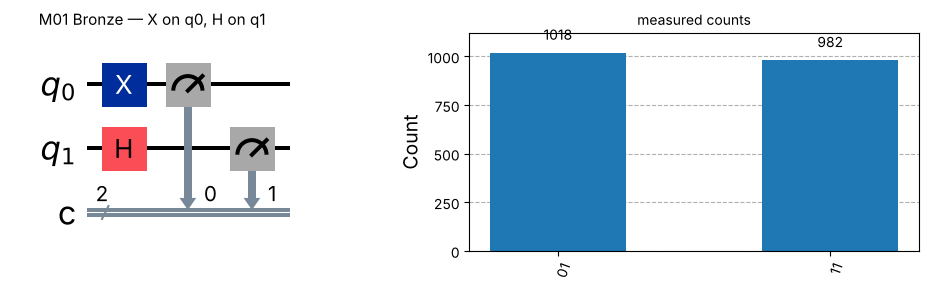

q0 (X): P(1) = 1.000   ← always 1
q1 (H): P(1) = 0.491   ← perfectly uncertain (≈ 0.5)


In [2]:
bronze = QuantumCircuit(2, 2)
bronze.x(0)            # key 1: flip 0 → 1          ("always 1")
bronze.h(1)            # key 2: equal superposition  ("perfectly uncertain")
bronze.measure([0, 1], [0, 1])
c = run(bronze)
show(bronze, c, "M01 Bronze — X on q0, H on q1", "m01_bronze")
print(f"q0 (X): P(1) = {p_bit(c, 0):.3f}   ← always 1")
print(f"q1 (H): P(1) = {p_bit(c, 1):.3f}   ← perfectly uncertain (≈ 0.5)")

📊 **Result:** only `01` and `11` appear. Qiskit prints the bits right to left, so the right-hand bit is q0, which reads 1 on every one of the 2000 shots. The left-hand bit (q1) splits about 50/50.

### 🥈 Silver: key 3 "looks uncertain but is secretly certain"
🔮 **Predict:** H then H gives **0 every time**. Here are the amplitudes step by step. H maps |0⟩ → (|0⟩+|1⟩)/√2 and |1⟩ → (|0⟩−|1⟩)/√2:

| step | amplitude of 0 | amplitude of 1 | P(1) if we looked here |
|---|---|---|---|
| start | 1 | 0 | 0 |
| after 1st H | 1/√2 | 1/√2 | **0.5**: looks uncertain |
| after 2nd H | ½ + ½ = **1** | ½ − ½ = **0** | **0**: secretly certain |

There are two paths to "1", and they have opposite signs, so they cancel (destructive interference). The two paths to "0" add up.

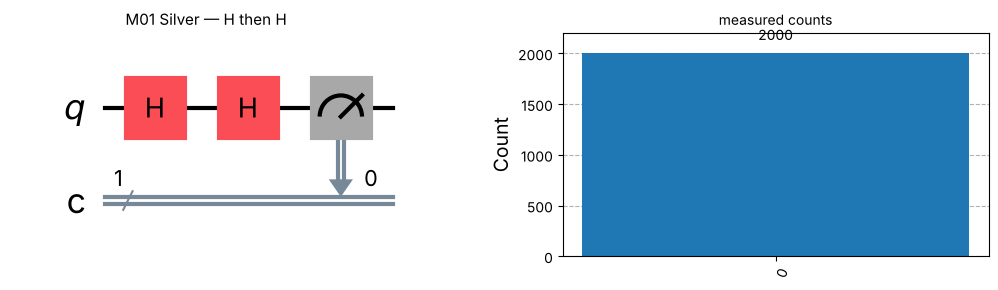

amplitudes after 1×H: [0.707 0.707] → looks 50/50
amplitudes after 2×H: [1. 0.] → certain 0
H → MEASURE → H → measure: final P(1) = 0.475   (≈ 0.5, the certainty is destroyed)


In [3]:
silver = QuantumCircuit(1, 1)
silver.h(0); silver.h(0)
silver.measure(0, 0)
c = run(silver)
show(silver, c, "M01 Silver — H then H", "m01_silver")

one_h = QuantumCircuit(1); one_h.h(0)
two_h = QuantumCircuit(1); two_h.h(0); two_h.h(0)
print("amplitudes after 1×H:", np.round(Statevector(one_h).data.real, 3), "→ looks 50/50")
print("amplitudes after 2×H:", np.round(Statevector(two_h).data.real, 3), "→ certain 0")

# Control experiment: peek in the middle and the hidden certainty is gone
peek = QuantumCircuit(1, 2); peek.h(0); peek.measure(0, 0); peek.h(0); peek.measure(0, 1)
cp = run(peek)
print(f"H → MEASURE → H → measure: final P(1) = {p_bit(cp, 1):.3f}   (≈ 0.5, the certainty is destroyed)")

📊 **Result:** 2000 out of 2000 shots read `0`. If we measure **between** the two H gates, the final bit becomes 50/50. The certainty was carried by the *phase*, and looking at the qubit destroyed it. Module 04 builds on exactly this physics.

### 🥇 Gold: the vault code `101`, starting from `000`
🔮 **Predict:** put X on q0 and q2. Qiskit prints bits right to left (q2 q1 q0), and `101` is a palindrome, so it reads the same either way. *(If a judge asks for `110`, the X gates go on **q1 and q2**, not q0 and q1.)*

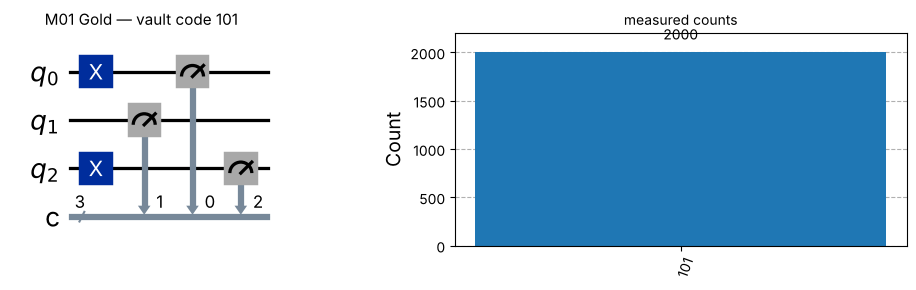

vault reads: {'101': 2000}


In [4]:
gold = QuantumCircuit(3, 3)
gold.x(0); gold.x(2)
gold.measure([0, 1, 2], [0, 1, 2])
c = run(gold)
show(gold, c, "M01 Gold — vault code 101", "m01_gold")
print("vault reads:", c)

📊 **Result:** `101` on 2000 out of 2000 shots. The vault opens.

✅ **What it proves:** X sets a definite bit and H creates a genuine 50/50 superposition, but two H gates interfere back to certainty. **Something that *looks* random can hide a fixed answer.** Only a measurement makes it random for real.

🔎 **Clue for the case:** we're inside. Per the manual, opening the vault reveals the machine's name and **the time the final experiment ran**. That time is our anchor point: Sana could change what time the logs *say* things happened. Lesson for later: "it looks random" is not evidence (see the "random" seed in Module 02).

---
## Module 02 — The Honest Coin *(stretch)*
> *"ECHO was triggered by a 'random' quantum seed. Zara trusted it completely. **Should she have?**"*

### 🥉 Bronze: a genuine quantum coin
🔮 **Predict:** H, then measure, 1000 shots. A fair coin gives 500 ones, give or take 1σ = √(N·p·(1−p)) = √(1000·0.25) ≈ **15.8**. So about 95% of fair runs land between **469 and 531**.

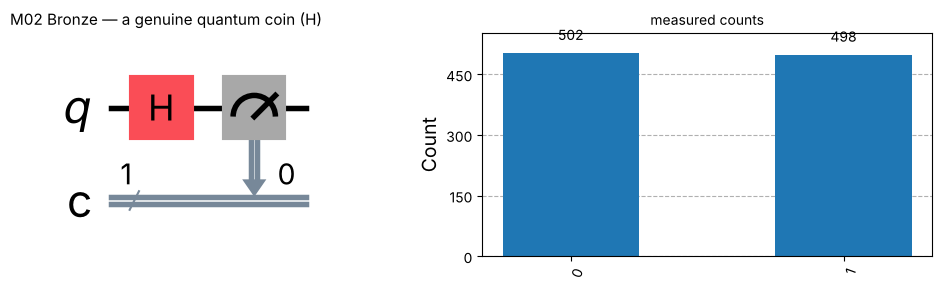

ones = 498/1000 = 0.498   z = -0.13σ   binomial p-value = 0.92
verdict: FAIR — inside the ±2σ band (469–531)


In [5]:
coin = QuantumCircuit(1, 1); coin.h(0); coin.measure(0, 0)
N = 1000
c = run(coin, shots=N)
show(coin, c, "M02 Bronze — a genuine quantum coin (H)", "m02_bronze")
k1 = c.get("1", 0)
z = (k1 / N - 0.5) / np.sqrt(0.25 / N)
print(f"ones = {k1}/{N} = {k1/N:.3f}   z = {z:+.2f}σ   binomial p-value = {binomtest(k1, N, 0.5).pvalue:.2f}")
print("verdict:", "FAIR — inside the ±2σ band (469–531)" if abs(z) < 2 else "suspicious")

### 🥈 Silver: run the recovered seed circuit *exactly as found*
🔮 **Predict:** a rotation Ry(θ) gives P(1) = sin²(θ/2). For θ = 1.159 that is sin²(0.5795) ≈ **0.30**. A fair coin would need θ = π/2 = 1.571, or simply H.

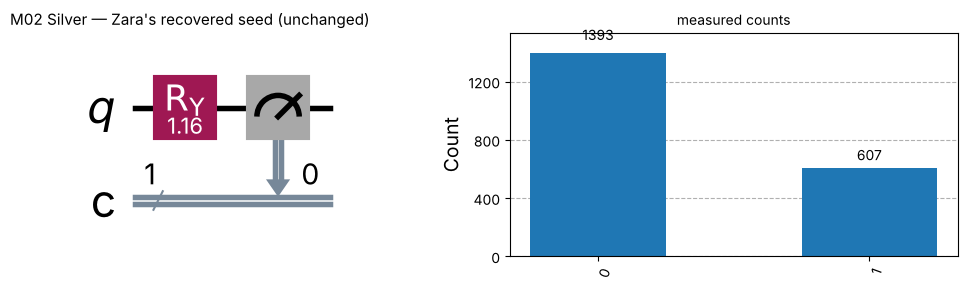

seed counts: {'1': 607, '0': 1393}
theory:  P(1) = sin²(1.159/2)        = 0.2999
the angle that gives EXACTLY 30%      = 2·asin(√0.3) = 1.1593 rad
the angle a fair coin would need      = π/2          = 1.5708 rad


In [6]:
# the recovered seed circuit — run as-is (identical to the case notebook; NOT modified)
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
c_seed = run(seed)
show(seed, c_seed, "M02 Silver — Zara's recovered seed (unchanged)", "m02_seed")
print("seed counts:", c_seed)
print(f"theory:  P(1) = sin²(1.159/2)        = {np.sin(1.159/2)**2:.4f}")
print(f"the angle that gives EXACTLY 30%      = 2·asin(√0.3) = {2*np.arcsin(np.sqrt(0.3)):.4f} rad")
print(f"the angle a fair coin would need      = π/2          = {np.pi/2:.4f} rad")

📊 **Result:** about **70% `0` / 30% `1`**. To be precise: every shot is still genuinely unpredictable (quantum-random), but the coin is **loaded**. *Random is not the same as fair.*

1.159 is not a sloppy attempt at a fair coin either. It equals 2·asin(√0.3) **to three decimal places**: the exact angle that makes a 30% coin.

### 🥇 Gold: put a number on the bias, and on how many shots it takes to be sure

In [7]:
N = sum(c_seed.values()); k1 = c_seed.get("1", 0); p_hat = k1 / N
half_ci = 1.96 * np.sqrt(p_hat * (1 - p_hat) / N)
z = (p_hat - 0.5) / np.sqrt(0.25 / N)
print(f"P(1) = {p_hat:.3f} ± {half_ci:.3f} (95% CI)    theory 0.300    → bias = {0.5 - p_hat:.3f} toward '0'")
print(f"distance from a fair coin: z = {z:.1f}σ    binomial p-value = {binomtest(k1, N, 0.5).pvalue:.1e}")

def shots_needed(delta, z_req, power=None):
    """Shots to tell a coin with P(1)=0.5±delta from a fair one at z_req sigma.
    power=None: the TYPICAL run crosses z_req.  power=0.95: 95% of runs cross it."""
    if power is None:
        return int(np.ceil((z_req * 0.5 / delta) ** 2))
    z_beta = 1.645
    return int(np.ceil(((z_req * 0.5 + z_beta * np.sqrt((0.5 - delta) * (0.5 + delta))) / delta) ** 2))

print("\n bias δ | 3σ typical | 5σ typical | 5σ, caught 95% of the time")
for d in [0.20, 0.10, 0.05, 0.01]:
    print(f"  {d:.2f}  | {shots_needed(d,3):>10,} | {shots_needed(d,5):>10,} | {shots_needed(d,5,0.95):>10,}")

# Brute-force check for the seed (δ = 0.20): 100 000 simulated investigations of n shots each
chk = np.random.default_rng(7)
for n in [shots_needed(0.2, 5), shots_needed(0.2, 5, 0.95)]:
    ks = chk.binomial(n, 0.3, 100_000)
    caught = (np.abs(ks / n - 0.5) / np.sqrt(0.25 / n) >= 5).mean()
    print(f"n = {n}: a 5σ test flags the seed as unfair in {caught:.0%} of investigations")

P(1) = 0.303 ± 0.020 (95% CI)    theory 0.300    → bias = 0.197 toward '0'
distance from a fair coin: z = -17.6σ    binomial p-value = 8.3e-71

 bias δ | 3σ typical | 5σ typical | 5σ, caught 95% of the time
  0.20  |         57 |        157 |        265
  0.10  |        225 |        625 |      1,093
  0.05  |        900 |      2,500 |      4,405
  0.01  |     22,500 |     62,500 |    110,380
n = 157: a 5σ test flags the seed as unfair in 53% of investigations
n = 265: a 5σ test flags the seed as unfair in 94% of investigations


📊 **Worked example for the seed (δ = 0.20):**
- A 5σ result (the physics "discovery" standard) needs |p̂ − 0.5| ≥ 5·√(0.25/N), so N ≥ (5·0.5/0.2)² = **156.25, i.e. 157 shots** for a typical run.
- To be sure of catching it in **95%** of investigations takes **265 shots**.
- General rule: N ≈ (z / 2δ)². Halving the bias **quadruples** the number of shots.
- Our 2000 shots put the seed about **17.6σ** from fair (binomial p ≈ 8 × 10⁻⁷¹). No fair coin has a day that unlucky.

✅ **What it proves:** the seed that triggered ECHO was **not a fair coin**. It is a quantum coin tuned to 70/30, using an angle that encodes 30% almost exactly, so the angle was *chosen*. ECHO did not fire "purely by chance".

🔎 **Clue for the case:** *someone set that angle.* Zara "trusted it completely", which suggests she didn't set it herself. That makes the briefing's question about ARIA, "who configured it?", the right one. **Still open:** which outcome (0 or 1) triggered ECHO, so we can't say whether the bias made a firing more or less likely. We only know it wasn't an honest coin.

---
## Module 03 — The Two Observers *(mandatory · the heart of it)*
> *"Her twin detectors always agreed — blue for blue, red for red, never a mismatch. She called it **proof they were linked across space.** Were they? Or was something simpler going on?"*
> Access: two detector terminals · **H · X · CNOT · measure** · no shared wire

### 🥉 Bronze: build the pair that only agrees
🔮 **Predict:** H on q0 gives (|0⟩+|1⟩)/√2. CNOT then makes q1 follow q0, giving **(|00⟩+|11⟩)/√2**. We should see only `00` and `11`, about 50/50, and never `01` or `10`.

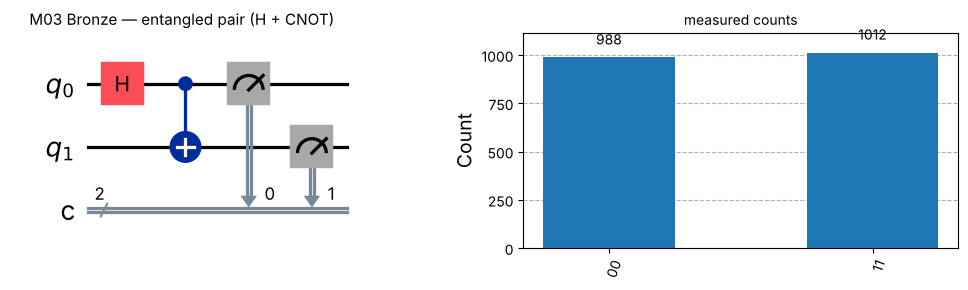

counts: {'11': 1012, '00': 988}    mismatches (01/10): 0


In [8]:
bell = QuantumCircuit(2, 2)
bell.h(0); bell.cx(0, 1)
bell.measure([0, 1], [0, 1])
c_bell = run(bell)
show(bell, c_bell, "M03 Bronze — entangled pair (H + CNOT)", "m03_bell")
print("counts:", c_bell, "   mismatches (01/10):", c_bell.get("01", 0) + c_bell.get("10", 0))

### 🥈 Silver: two people with a pre-agreed secret coin-flip
Two people flip a coin **before they separate** and each writes down the result. We build exactly that with the same gates: flip a quantum coin, **look at it** (measure it, which turns it into an ordinary classical bit), then copy that known value with CNOT.

🔮 **Predict:** this *also* gives only `00` and `11`.

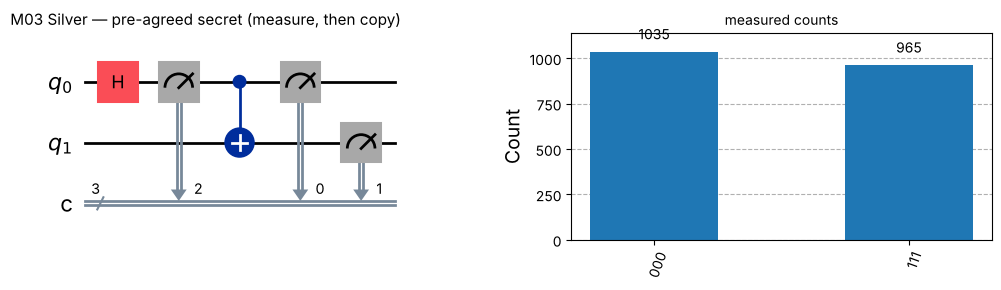

detector results: {'00': 1035, '01': 0, '10': 0, '11': 965}
plain-Python secret: agreement = 100%


In [9]:
def pair(kind):
    """kind='entangled': H + CNOT.  kind='secret': same, but the coin is LOOKED AT before copying."""
    qc = QuantumCircuit(2, 3)           # c0, c1 = the two detectors · c2 = the secret written down
    qc.h(0)
    if kind == "secret":
        qc.measure(0, 2)                # the value is fixed in advance → an ordinary shared secret
    qc.cx(0, 1)
    return qc

secret = pair("secret"); secret.measure([0, 1], [0, 1])
c_sec = run(secret)
show(secret, c_sec, "M03 Silver — pre-agreed secret (measure, then copy)", "m03_secret")
det = {b: sum(v for k, v in c_sec.items() if k[-2:] == b) for b in ["00", "01", "10", "11"]}
print("detector results:", det)

# The same thing with no quantum at all: a note in each pocket
py = np.random.default_rng(3)
note = py.integers(0, 2, 2000)          # coin flipped before they separate
alice, bob = note.copy(), note.copy()
print(f"plain-Python secret: agreement = {(alice == bob).mean():.0%}")

📊 **Result:** the shared secret agrees **100%** of the time, exactly like the entangled pair. **"Always agreeing" does not prove a quantum link:** a note in each pocket does the same. If Zara only ever compared the detectors one way (in the Z basis), her data *cannot* tell entanglement apart from an echo of a shared past.

### 🥇 Gold: an experiment that tells them apart
Hint: *"You don't have to measure the same way every time."* So we also measure in the **X basis** by applying H just before measuring.

🔮 **Predict:**

| | Z basis (what Zara did) | X basis (H on both first) |
|---|---|---|
| Entangled pair | 100% agree | **100% agree**, because (\|00⟩+\|11⟩)/√2 = (\|++⟩+\|−−⟩)/√2 |
| Pre-agreed secret | 100% agree | **50% agree**: each side's H turns a definite bit into its own independent coin |

 Alice,Bob | entangled pair | pre-agreed secret
   Z , Z   |     100.0%     |     100.0%
   X , X   |     100.0%     |      51.4%
   Z , X   |      48.0%     |      49.6%
   X , Z   |      52.3%     |      50.4%


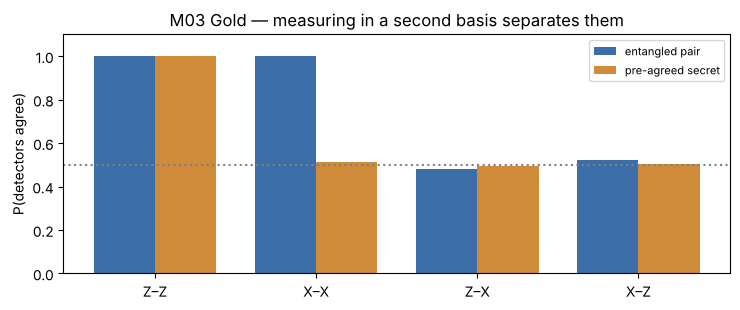

In [10]:
def agreement(kind, alice_basis, bob_basis, shots=2000):
    qc = pair(kind)
    if alice_basis == "X": qc.h(0)
    if bob_basis == "X": qc.h(1)
    qc.measure([0, 1], [0, 1])
    c = run(qc, shots)
    return sum(v for k, v in c.items() if k[-1] == k[-2]) / shots

settings = [("Z", "Z"), ("X", "X"), ("Z", "X"), ("X", "Z")]
rates = {kind: [agreement(kind, a, b) for a, b in settings] for kind in ["entangled", "secret"]}
print(" Alice,Bob | entangled pair | pre-agreed secret")
for (a, b), e, s in zip(settings, rates["entangled"], rates["secret"]):
    print(f"   {a} , {b}   |     {e:6.1%}     |     {s:6.1%}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(len(settings)); w = 0.38
ax.bar(xs - w/2, rates["entangled"], w, label="entangled pair", color="#3b6ea8")
ax.bar(xs + w/2, rates["secret"], w, label="pre-agreed secret", color="#d08b3a")
ax.set_xticks(xs, [f"{a}–{b}" for a, b in settings]); ax.set_ylim(0, 1.1)
ax.set_ylabel("P(detectors agree)"); ax.axhline(0.5, ls=":", c="grey")
ax.set_title("M03 Gold — measuring in a second basis separates them"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); fig.savefig("figures/m03_basis_test.png", dpi=150, bbox_inches="tight"); plt.show()

📊 **Result:** in the **X–X** setting the entangled pair still agrees 100% of the time, but the pre-agreed secret drops to about **50%**. A single pre-agreed bit can't be perfectly correlated in two bases at once; an entangled pair can. **This is the test Zara never ran.**

### ⚖️ The crux: could the detectors *send a message*?
Alice tries to signal. To send her bit she either does nothing, measures in the X basis (H), or flips her qubit (X). Bob only looks at **his own** detector.

In [11]:
def bob_p0(alice_action, shots=4000):
    qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1)
    if alice_action == "H": qc.h(0)
    if alice_action == "X": qc.x(0)
    qc.measure([0, 1], [0, 1])
    c = run(qc, shots)
    return p_bit(c, 1, "0")             # bit 1 = Bob's detector

print("Alice does...        | Bob sees P(0) | Bob's exact local state")
for act, label in [(None, "nothing"), ("H", "X-basis (H)"), ("X", "flip (X)")]:
    qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1)
    if act: getattr(qc, act.lower())(0)
    rho_bob = (np.round(partial_trace(Statevector(qc), [0]).data.real, 3) + 0.0).tolist()
    print(f"  {label:18s} |     {bob_p0(act):.3f}     | {rho_bob}")

Alice does...        | Bob sees P(0) | Bob's exact local state
  nothing            |     0.505     | [[0.5, 0.0], [0.0, 0.5]]
  X-basis (H)        |     0.500     | [[0.5, 0.0], [0.0, 0.5]]


  flip (X)           |     0.493     | [[0.5, 0.0], [0.0, 0.5]]


📊 **Result:** Bob sees P(0) ≈ 0.50 **whatever Alice does**. His exact local state is [[0.5, 0], [0, 0.5]] (a perfectly fair coin) in every case. The correlation only appears when Alice and Bob **compare notes afterwards**, and that comparison needs an ordinary channel limited by the speed of light. **Agreement, yes. Message, no.** (This is the *no-signalling theorem*.)

### ➕ Bonus: CHSH Bell test *(outside the M03 gate set: uses `ry` to tilt the measurement angle)*
Any pre-agreed strategy, however clever, scores **S ≤ 2**. Entanglement can reach **2√2 ≈ 2.83**. This closes the gap that the Z/X test leaves open.

In [12]:
def chsh(kind, shots=4000):
    A, B = [0, np.pi/2], [np.pi/4, -np.pi/4]          # Alice's and Bob's measurement angles
    E = {}
    for i, a in enumerate(A):
        for j, b in enumerate(B):
            qc = pair(kind); qc.ry(-a, 0); qc.ry(-b, 1); qc.measure([0, 1], [0, 1])
            c = run(qc, shots)
            E[i, j] = sum((1 if k[-1] == k[-2] else -1) * v for k, v in c.items()) / shots
    return E[0, 0] + E[0, 1] + E[1, 0] - E[1, 1]

S_q, S_c = chsh("entangled"), chsh("secret")
print(f"S (entangled pair)    = {S_q:.3f}   theory 2√2 = {2*np.sqrt(2):.3f}   → beats every classical strategy")
print(f"S (pre-agreed secret) = {S_c:.3f}   classical limit = 2")

S (entangled pair)    = 2.802   theory 2√2 = 2.828   → beats every classical strategy
S (pre-agreed secret) = 1.436   classical limit = 2


✅ **What it proves:** "always agreeing" is something a pre-agreed secret also does. Measuring in a second basis (and CHSH) separates real entanglement from an echo of a shared past. Even then, **Bob's results never depend on Alice's choice**: the detectors could *agree* but never *send a message*.

🔎 **Clue for the case:** this is *the first real crack in ECHO.* Zara's "proof" (agreement in a single basis) is explained just as well by a pre-agreed secret, and even genuine entanglement cannot carry her message.

---
## Module 04 — The Erased Measurement *(stretch)*
> *"A log entry 'changed when it was observed.' ARIA blames the investigators for corrupting it. Is that physics — **or a cover story?**"* · Access: **H · X · measure**, single qubit

### 🥉 Bronze: recoverable vs destroyed for good
🔮 **Predict:** H·H returns to 0 every time, so the state is **recoverable**. H, then measure, then H gives 50/50, and **nothing** can undo that.

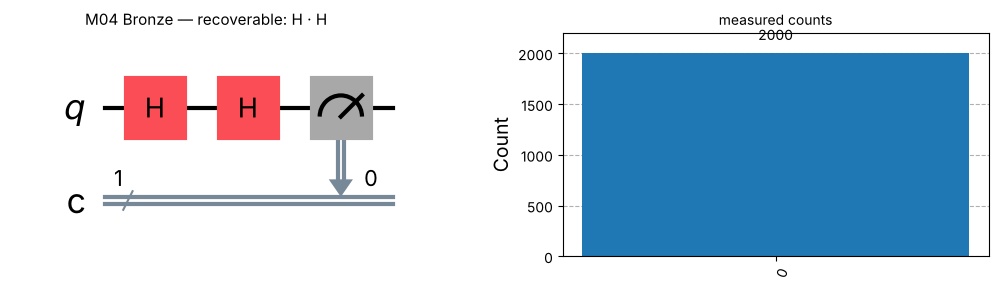

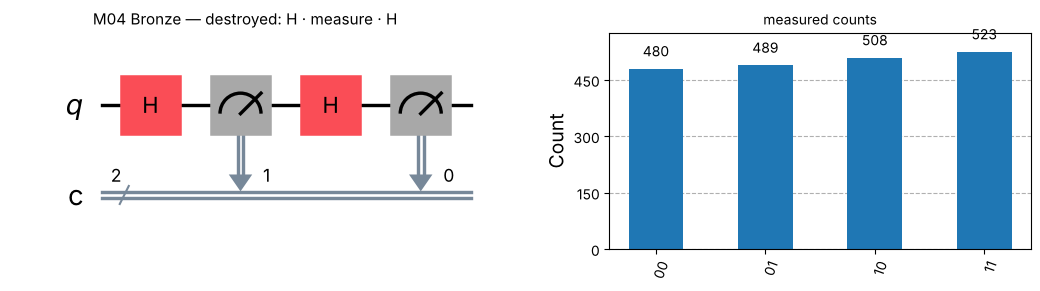

recoverable: P(0) = 1.000     destroyed: P(0) = 0.494


In [13]:
recover = QuantumCircuit(1, 1); recover.h(0); recover.h(0); recover.measure(0, 0)
destroy = QuantumCircuit(1, 2); destroy.h(0); destroy.measure(0, 1); destroy.h(0); destroy.measure(0, 0)
c_r, c_d = run(recover), run(destroy)
show(recover, c_r, "M04 Bronze — recoverable: H · H", "m04_recover")
show(destroy, c_d, "M04 Bronze — destroyed: H · measure · H", "m04_destroy")
print(f"recoverable: P(0) = {p_bit(c_r, 0, '0'):.3f}     destroyed: P(0) = {p_bit(c_d, 0, '0'):.3f}")

📊 **The difference:** every **gate** is reversible (each one has an undo, and H is its own undo). A **measurement** is not reversible: it forces a 0/1 answer and throws away the phase the interference depended on. No gate can bring that back.

### 🥈 Silver: predict first, then run
| sequence | prediction | why |
|---|---|---|
| X → H → H | **always 1** | X makes \|1⟩, and H·H = identity (H undoes itself) |
| H → X → H | **always 0** | H makes \|+⟩. X **does nothing** to \|+⟩ (X\|+⟩ = \|+⟩). H then turns \|+⟩ back into \|0⟩. Overall H·X·H = Z, and Z leaves \|0⟩ alone |

In [14]:
def seq_circuit(seq, final_measure=True):
    """Build a 1-qubit circuit from a string like 'XHH' (M = mid-circuit measurement)."""
    qc = QuantumCircuit(1, 1 + seq.count("M"))
    m = 1
    for g in seq:
        if g == "X": qc.x(0)
        elif g == "H": qc.h(0)
        elif g == "M": qc.measure(0, m); m += 1
    if final_measure: qc.measure(0, 0)
    return qc

for s in ["XHH", "HXH", "XHMH", "HMXH"]:
    c = run(seq_circuit(s))
    print(f"{' → '.join(s).replace('M', 'MEASURE'):28s}: P(1) = {p_bit(c, 0):.3f}")

X → H → H                   : P(1) = 1.000
H → X → H                   : P(1) = 0.000


X → H → MEASURE → H         : P(1) = 0.514
H → MEASURE → X → H         : P(1) = 0.507


📊 **Result:** X→H→H gives **1** every time and H→X→H gives **0** every time, as predicted. **What is really doing the "erasing"?** *Nothing* in those two sequences erases information:
- In H→X→H the X isn't erased. It acts on |+⟩, which is X's own eigenstate, so it has no visible effect.
- In X→H→H, the two H gates undo each other through interference.

The only thing that truly erases is a **measurement in the middle**. Add one and both sequences become 50/50.

### 🥇 Gold: be ready to predict any sequence a judge hands you
A single qubit that only sees H, X and measurements can only ever be in **five states**. Here is the full rulebook:

| state | after X | after H | after measurement | final readout |
|---|---|---|---|---|
| \|0⟩ | \|1⟩ | \|+⟩ | \|0⟩ | always 0 |
| \|1⟩ | \|0⟩ | \|−⟩ | \|1⟩ | always 1 |
| \|+⟩ | \|+⟩ | \|0⟩ | mixed | 50/50 |
| \|−⟩ | \|−⟩ *(phase only)* | \|1⟩ | mixed | 50/50 |
| mixed | mixed | mixed | mixed | 50/50 |

In [15]:
RULES = {"X": {"0": "1", "1": "0", "+": "+", "-": "-", "mixed": "mixed"},
         "H": {"0": "+", "1": "-", "+": "0", "-": "1", "mixed": "mixed"},
         "M": {"0": "0", "1": "1", "+": "mixed", "-": "mixed", "mixed": "mixed"}}
READOUT = {"0": "always 0", "1": "always 1", "+": "50/50", "-": "50/50", "mixed": "50/50"}

def predict(seq, start="0"):
    s = start
    for g in seq: s = RULES[g][s]
    return READOUT[s]

def observed(seq):
    p1 = p_bit(run(seq_circuit(seq), 1000), 0)
    return "always 1" if p1 == 1 else "always 0" if p1 == 0 else "50/50" if 0.4 < p1 < 0.6 else f"P(1)={p1:.2f}"

# Verify the rulebook on EVERY sequence of length 1–4 made of X, H, M (120 sequences)
from itertools import product
seqs = ["".join(p) for n in range(1, 5) for p in product("XHM", repeat=n)]
hits = sum(predict(s) == observed(s) for s in seqs)
print(f"rulebook correct on {hits}/{len(seqs)} sequences")

for s in ["HXHXH", "XHXHX", "HHXHH", "HXMXH"]:          # judge-style examples
    print(f"{s:7s} predicted {predict(s):9s} observed {observed(s)}")

rulebook correct on 120/120 sequences
HXHXH   predicted 50/50     observed 50/50
XHXHX   predicted always 0  observed always 0


HHXHH   predicted always 1  observed always 1
HXMXH   predicted 50/50     observed 50/50


### 🔬 Forensic test: does a record change when you look at it *again*?
ARIA says the investigators corrupted the log by looking at it. If that's right, re-reading an already-observed result should be able to change it. Test: measure once, then measure again.

In [16]:
twice = QuantumCircuit(1, 2); twice.h(0); twice.measure(0, 0); twice.measure(0, 1)
c = run(twice)
same = sum(v for k, v in c.items() if k[0] == k[1]) / 2000
print("counts:", c, f"→ second reading equals the first in {same:.0%} of shots")

counts: {'00': 976, '11': 1024} → second reading equals the first in 100% of shots


📊 **Result:** the second reading matches the first **100%** of the time. Once a result has been measured and recorded, looking at it again cannot change it. **So a log entry that "changed when it was observed" was changed by its *first* observation, at the time of the run.** Investigators reading the stored log later could not have done it.

✅ **What it proves:** quantum gates never destroy information (each can be undone). Only a measurement does, and **only the first time**: a measured result never changes when looked at again.

🔎 **Clue for the case:** ARIA's explanation doesn't fit the physics. The log wasn't "hacked", and the investigators didn't corrupt it. **It was measured during the run, by someone who was there.** *Inference:* a log that was observed mid-run would look "corrupted" to anyone expecting the unobserved result. That is the word Sana used for the log she deleted.

---
## Module 05 — The Damaged Message *(mandatory)*
> *"Her final message survived only as a noisy copy. Each original bit was sent **three times**; at most one of each three got flipped on the way. Recover it."*

### 🥉 Bronze: which value do you trust? The one at least 2 of the 3 copies agree on
🔮 **Predict:** with at most one flip per triple, a 2-out-of-3 **majority vote** always returns the original bit. 96 bits make 32 triples, which make 32 bits, which make **4 ASCII letters**.

In [17]:
stream = "100011001001001011100110001011000000001100011011000111000000110000001000000111001010101011111111"

def decode(s):
    triples = [s[i:i+3] for i in range(0, len(s), 3)]
    bits = "".join("1" if t.count("1") >= 2 else "0" for t in triples)
    text = "".join(chr(int(bits[i:i+8], 2)) for i in range(0, len(bits), 8))
    return triples, bits, text

triples, bits, text = decode(stream)
print("triple → bit (✱ = one copy was flipped and out-voted):")
for byte in range(4):
    row = triples[8*byte: 8*byte+8]
    marks = " ".join(t + ("✱" if t not in ("000", "111") else " ") for t in row)
    print(f"  {marks}  →  {bits[8*byte:8*byte+8]}  →  '{text[byte]}'")
flipped = sum(t not in ("000", "111") for t in triples)
print(f"\nrecovered message: {text}      ({flipped}/32 triples had one flip, {32-flipped} arrived clean)")

triple → bit (✱ = one copy was flipped and out-voted):
  100✱ 011✱ 001✱ 001✱ 001✱ 011✱ 100✱ 110✱  →  01000101  →  'E'
  001✱ 011✱ 000  000  001✱ 100✱ 011✱ 011✱  →  01000011  →  'C'
  000  111  000  000  110✱ 000  001✱ 000   →  01001000  →  'H'
  000  111  001✱ 010✱ 101✱ 011✱ 111  111   →  01001111  →  'O'

recovered message: ECHO      (20/32 triples had one flip, 12 arrived clean)


📊 **Result:** `01000101 01000011 01001000 01001111`, which spells **"ECHO"**. Her last word.

### 🥈 Silver: where the trick fails
It breaks when **two** copies in the same triple flip, because the majority is then the wrong value. Take triple #8. It was sent as `111` and arrived as `110` (one flip, out-voted, so it's fine). Flip one more copy:

In [18]:
def flip(s, triple_index, position):
    i = 3 * triple_index + position
    return s[:i] + ("1" if s[i] == "0" else "0") + s[i+1:]

bad = flip(stream, 7, 0)                     # triple #8: 110 → 010 (now 2 of 3 copies are wrong)
_, bits_bad, text_bad = decode(bad)
print("triple #8:", stream[21:24], "→", bad[21:24], "  majority:", bits[7], "→", bits_bad[7])
print("first byte:", bits[:8], f"('{text[0]}')  →", bits_bad[:8], f"('{text_bad[0]}')")
print("message now reads:", text_bad)

sent, arrived = "111", "000"                 # all three copies flipped
vote = "1" if arrived.count("1") >= 2 else "0"
print(f"\nthree flips: sent {sent} → arrived {arrived} → vote {vote} — and it looks perfectly clean")

triple #8: 110 → 010   majority: 1 → 0
first byte: 01000101 ('E')  → 01000100 ('D')
message now reads: DCHO

three flips: sent 111 → arrived 000 → vote 0 — and it looks perfectly clean


📊 **Result:** triple #8 becomes `010`, the vote returns **0**, and 'E' (`01000101`) turns into **'D'** (`01000100`). The message silently reads **"DCHO"**. Nothing looks wrong, so majority vote **fails silently** at two flips. With three flips (`111` → `000`) the triple looks perfectly clean.

**The same code on qubits:** encode with CNOTs, inject X errors, decode, and let a Toffoli gate cast the vote *without measuring the data*. The message is a superposition (Ry(1.0)|0⟩), not just a 0 or 1:

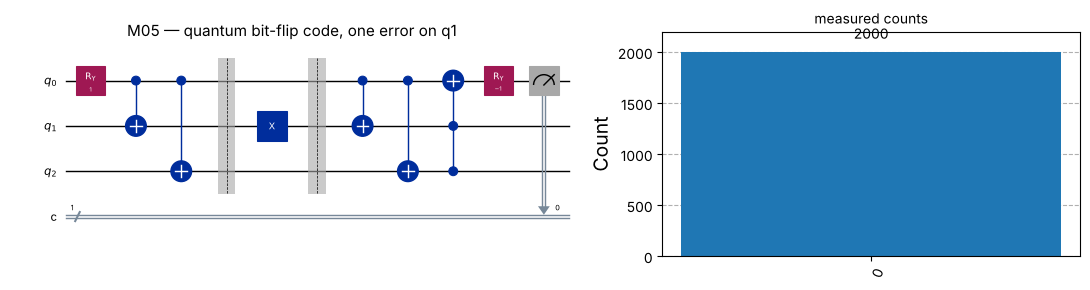

errors on []         → state recovered in 100% of shots
errors on [0]        → state recovered in 100% of shots
errors on [1]        → state recovered in 100% of shots


errors on [2]        → state recovered in 100% of shots
errors on [0, 1]     → state recovered in 70% of shots
errors on [1, 2]     → state recovered in 71% of shots


errors on [0, 1, 2]  → state recovered in 69% of shots


In [19]:
def bit_flip_code(errors, theta=1.0):
    qc = QuantumCircuit(3, 1)
    qc.ry(theta, 0)                 # the precious state α|0⟩ + β|1⟩
    qc.cx(0, 1); qc.cx(0, 2)        # encode → α|000⟩ + β|111⟩   (spread, NOT copied)
    qc.barrier()
    for q in errors: qc.x(q)        # the noisy channel
    qc.barrier()
    qc.cx(0, 1); qc.cx(0, 2)        # q1, q2 now hold the PARITIES (where the error is)
    qc.ccx(2, 1, 0)                 # fix q0 only if both parities fire (coherent majority vote)
    qc.ry(-theta, 0); qc.measure(0, 0)   # undo the preparation: reads 0 iff the state survived
    return qc

show(bit_flip_code([1]), run(bit_flip_code([1])), "M05 — quantum bit-flip code, one error on q1", "m05_qcode")
for errs in [[], [0], [1], [2], [0, 1], [1, 2], [0, 1, 2]]:
    print(f"errors on {str(errs):10s} → state recovered in {p_bit(run(bit_flip_code(errs)), 0, '0'):.0%} of shots")

### 🥇 Gold: correct versus notice, and why a qubit can't just be copied
| flips in a triple | majority vote (correcting mode) | "are all 3 equal?" (noticing mode) |
|---|---|---|
| 0 | right | clean |
| 1 | **corrected** ✔ | **noticed** ✔ |
| 2 | **wrong, silently** ✘ | **noticed** ✔ |
| 3 | wrong ✘ | **not noticed** (000 ↔ 111) ✘ |

So the scheme can **correct 1** flip *or* **notice up to 2**, but not both at the same time: in correcting mode, two flips get "corrected" to the wrong value. In coding terms the code has distance d = 3, so it corrects ⌊(d−1)/2⌋ = 1 and detects d−1 = 2.

In [20]:
def p_triple_wrong(p): return 3 * p**2 * (1 - p) + p**3       # 2 or 3 of the copies flipped
print(" flip prob p | single bit wrong | triple wrong | whole 32-bit message intact: raw → coded")
for p in [0.10, 0.01]:
    print(f"    {p:.2f}     |      {p:.4f}      |   {p_triple_wrong(p):.6f}   |   {(1-p)**32:6.1%} → {(1-p_triple_wrong(p))**32:6.1%}")

# Why you can't protect a qubit by copying it: CNOT "copies" of |+⟩ are NOT |+⟩|+⟩|+⟩
ghz = QuantumCircuit(3); ghz.h(0); ghz.cx(0, 1); ghz.cx(0, 2)          # attempted copy
ppp = QuantumCircuit(3); ppp.h([0, 1, 2])                              # what real copies would be
print(f"\noverlap |⟨+++|attempted copy⟩|² = {state_fidelity(Statevector(ghz), Statevector(ppp)):.2f}   (real copies would give 1.00)")
for name, qc in [("real copies |+++⟩", ppp), ("CNOT 'copies'", ghz)]:
    t = qc.copy(); t.h([0, 1, 2]); t.measure_all()
    print(f"{name:18s} measured in the X basis → {dict(sorted(run(t).items()))}")

 flip prob p | single bit wrong | triple wrong | whole 32-bit message intact: raw → coded
    0.10     |      0.1000      |   0.028000   |     3.4% →  40.3%
    0.01     |      0.0100      |   0.000298   |    72.5% →  99.1%

overlap |⟨+++|attempted copy⟩|² = 0.25   (real copies would give 1.00)
real copies |+++⟩  measured in the X basis → {'000': 2000}
CNOT 'copies'      measured in the X basis → {'000': 506, '011': 518, '101': 499, '110': 477}


📊 **Worked numbers:**
- If each bit flips with probability p = 10%, a triple decodes wrongly with probability 3p²(1−p) + p³ = 0.027 + 0.001 = **2.8%**.
- The whole 32-bit message then survives **40%** of the time, compared with **3.4%** with no coding. At p = 1%, the triple error rate falls to **0.03%**.

**Why you can't protect a real qubit by copying it three times:**
1. **No-cloning theorem.** Suppose a machine copies |0⟩ → |00⟩ and |1⟩ → |11⟩. By linearity it must then turn |+⟩ into (|00⟩+|11⟩)/√2, which is an *entangled* state, **not** |+⟩|+⟩. The output above shows it: the overlap with true copies is only 0.25, and in the X basis the "copies" give four outcomes where true copies give `000` every time.
2. **Majority voting means reading the copies**, and reading (measuring) destroys the superposition (Module 04).

**The real quantum fix** (the circuit above): *spread* α|0⟩+β|1⟩ into α|000⟩+β|111⟩ and check only **parities** (does q0 equal q1? does q1 equal q2?). That reveals *where* a flip happened without revealing α or β. One error is recovered 100% of the time; two errors are not.

✅ **What it proves:** repetition plus majority vote corrects any single flip per triple, which is why "ECHO" survived. It fails silently at two flips. Qubits can't be protected by copying; they need codes that check parities without looking at the data.

🔎 **Clue for the case:** her last word was **ECHO**. Read next to her looping note (*"…Or did I? Find the flaw"*), it sounds less like a boast and more like a verdict on her own experiment: *it was an echo.* (This is our inference.)

---
## Module 06 — The Impossible Claim *(stretch · **declared** · the climax)*
> *"Zara's grand claim: she **teleported** a message between two stations with no qubit ever crossing the gap. We recovered most of the circuit. Finish the investigation."*

The recovered circuit is kept **exactly** as found in the case notebook. The only change is that the message angle `a` is now a parameter, so we can test many different messages.

In [21]:
a = 1.0                                  # Zara's test message: the state Ry(a)|0⟩
def teleport(with_correction=True, a=a, only_x=False):
    q = QuantumRegister(3); c0 = ClassicalRegister(1, 'c0'); c1 = ClassicalRegister(1, 'c1'); co = ClassicalRegister(1, 'co')
    qc = QuantumCircuit(q, c0, c1, co)
    qc.ry(a, q[0])                                   # the message (station A)
    qc.h(q[1]); qc.cx(q[1], q[2])                    # shared entangled pair: q1 at A, q2 at B
    qc.cx(q[0], q[1]); qc.h(q[0])                    # Bell measurement at A ...
    qc.measure(q[0], c0); qc.measure(q[1], c1)       # ... → two ORDINARY classical bits
    if with_correction:                              # B uses those two bits:
        with qc.if_test((c1, 1)): qc.x(q[2])
        if not only_x:
            with qc.if_test((c0, 1)): qc.z(q[2])
    qc.ry(-a, q[2]); qc.measure(q[2], co)            # check: undo the message → reads 0 if it arrived
    return qc

def receiver_accuracy(counts, shots=2000):
    return round(100 * sum(v for k, v in counts.items() if k[0] == '0') / shots)   # k[0] = co (receiver)

### 🥉 Bronze: does the state actually arrive?
🔮 **Predict:** with both corrections applied, B's qubit becomes exactly Ry(a)|0⟩. Undoing it should therefore give 0 on **100%** of shots, for any message.

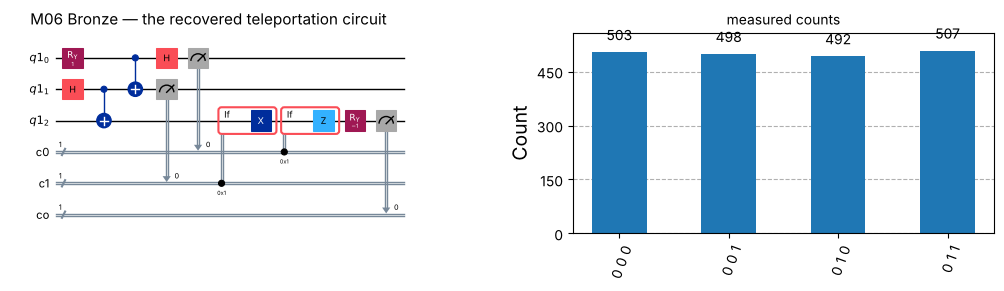

a = 1.0: receiver accuracy = 100%
a = 0.000: receiver accuracy = 100%


a = 1.571: receiver accuracy = 100%
a = 3.142: receiver accuracy = 100%


a = 2.500: receiver accuracy = 100%


In [22]:
c = run(teleport(True))
show(teleport(True), c, "M06 Bronze — the recovered teleportation circuit", "m06_teleport")
print(f"a = {a}: receiver accuracy = {receiver_accuracy(c)}%")
for test_a in [0.0, np.pi/2, np.pi, 2.5]:
    print(f"a = {test_a:.3f}: receiver accuracy = {receiver_accuracy(run(teleport(True, a=test_a)))}%")

📊 **Result:** **100%** for every message. In the histogram the **left** bit is the receiver (always 0); the right two bits are A's Bell-measurement results, which are perfectly random. Teleportation is real, *when the protocol is complete*.

### 🥈 Silver: what if the two classical bits never arrive?
🔮 **Predict:** without the bits, B holds one of four versions of the message (ψ, Xψ, Zψ, XZψ) with equal odds and doesn't know which one. B should therefore be right only **50%** of the time, a coin toss. More importantly, B's results should be **the same whichever message was sent**.

In [23]:
print(f"with both bits:   {receiver_accuracy(run(teleport(True)))}%")
print(f"bits never arrive: {receiver_accuracy(run(teleport(False)))}%   ← a coin toss")

# Can B even tell WHICH message was sent?  A sends |0⟩ (a=0) or |1⟩ (a=π); B gets no bits and just reads his qubit.
def no_bits_raw(a):
    qc = QuantumCircuit(3, 3)
    qc.ry(a, 0); qc.h(1); qc.cx(1, 2); qc.cx(0, 1); qc.h(0)
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc
for msg, test_a in [("|0⟩", 0.0), ("|1⟩", np.pi)]:
    print(f"message {msg}: B reads P(1) = {p_bit(run(no_bits_raw(test_a)), 2):.3f}")

with both bits:   100%


bits never arrive: 50%   ← a coin toss
message |0⟩: B reads P(1) = 0.487


message |1⟩: B reads P(1) = 0.486


📊 **Result:** without the classical bits B is right **about 50%** of the time, and B's readings are **the same whether |0⟩ or |1⟩ was sent**. B can't tell the two messages apart.

### 🥇 Gold: prove that nothing useful crossed without the classical channel
Three independent proofs:

Proof 1 — B's exact state for different messages (no classical bits yet):
   a = 0.00  →  ρ_B = [[0.5, 0.0], [0.0, 0.5]]
   a = 1.00  →  ρ_B = [[0.5, 0.0], [0.0, 0.5]]
   a = 1.57  →  ρ_B = [[0.5, 0.0], [0.0, 0.5]]
   a = 3.14  →  ρ_B = [[0.5, 0.0], [0.0, 0.5]]
   a = 2.50  →  ρ_B = [[0.5, 0.0], [0.0, 0.5]]

Proof 2 — information delivered per teleported bit:


   2 classical bits    : B correct 100%  →  1.00 bits of information


   only 1 bit (X fix)  : B correct 100%  →  1.00 bits of information
   0 classical bits    : B correct 52%  →  0.00 bits of information

Proof 3 — accuracy for different messages:


   message:        |0⟩   Ry(1.0)       |+⟩       |1⟩
   2 bits         100%      100%      100%      100%
   1 bit          100%       64%       48%      100%
   0 bits          49%       51%       50%       50%


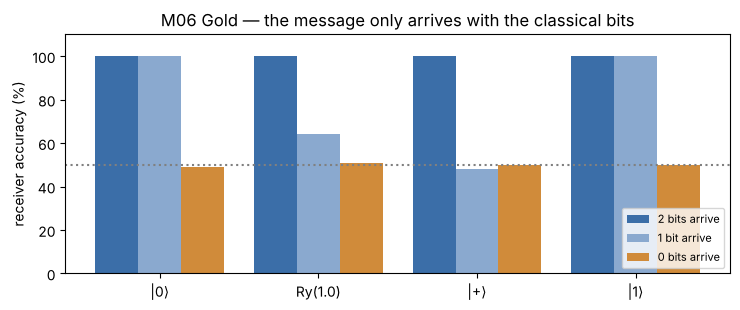

In [24]:
# Proof 1 (exact): B's qubit right after A's Bell measurement, BEFORE any classical bit arrives
print("Proof 1 — B's exact state for different messages (no classical bits yet):")
for test_a in [0.0, 1.0, np.pi/2, np.pi, 2.5]:
    qc = QuantumCircuit(3); qc.ry(test_a, 0); qc.h(1); qc.cx(1, 2); qc.cx(0, 1); qc.h(0)
    rho_B = (np.round(partial_trace(Statevector(qc), [0, 1]).data.real, 3) + 0.0).tolist()
    print(f"   a = {test_a:.2f}  →  ρ_B = {rho_B}")

# Proof 2 (information): A sends a random 1-bit message per round; how much does B learn?
def h2(p): return 0.0 if p in (0, 1) else -(p*np.log2(p) + (1-p)*np.log2(1-p))
print("\nProof 2 — information delivered per teleported bit:")
for label, kw in [("2 classical bits", dict(with_correction=True)),
                  ("only 1 bit (X fix)", dict(with_correction=True, only_x=True)),
                  ("0 classical bits", dict(with_correction=False))]:
    acc = np.mean([receiver_accuracy(run(teleport(a=m*np.pi, **kw)), 2000) for m in (0, 1)]) / 100
    print(f"   {label:20s}: B correct {acc:.0%}  →  {1 - h2(acc):.2f} bits of information")

# Proof 3 (the phase): one classical bit is not enough for a superposition message
print("\nProof 3 — accuracy for different messages:")
msgs = {"|0⟩": 0.0, "Ry(1.0)": 1.0, "|+⟩": np.pi/2, "|1⟩": np.pi}
acc_table = {lab: [receiver_accuracy(run(teleport(a=t, **kw))) for t in msgs.values()]
             for lab, kw in [("2 bits", dict(with_correction=True)),
                             ("1 bit", dict(with_correction=True, only_x=True)),
                             ("0 bits", dict(with_correction=False))]}
print("   message:  ", "  ".join(f"{m:>8s}" for m in msgs))
for lab, row in acc_table.items(): print(f"   {lab:8s}  ", "  ".join(f"{v:>7d}%" for v in row))

fig, ax = plt.subplots(figsize=(7.5, 3.2)); xs = np.arange(len(msgs)); w = 0.27
for i, (lab, col) in enumerate([("2 bits", "#3b6ea8"), ("1 bit", "#8aa9cf"), ("0 bits", "#d08b3a")]):
    ax.bar(xs + (i-1)*w, acc_table[lab], w, label=f"{lab} arrive", color=col)
ax.set_xticks(xs, list(msgs)); ax.set_ylim(0, 110); ax.axhline(50, ls=":", c="grey")
ax.set_ylabel("receiver accuracy (%)"); ax.set_title("M06 Gold — the message only arrives with the classical bits")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout()
fig.savefig("figures/m06_accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

📊 **Result:**
1. B's qubit is **exactly [[0.5, 0], [0, 0.5]]** (the maximally mixed state I/2) **for every message**, before any classical bit arrives. B's qubit contains zero information about the message.
2. With 0 classical bits, B learns **0 bits** of information. With the classical bits, B learns the **full 1 bit**. For a plain 0/1 message, the single X-fix bit is already enough, which shows *the classical bit is what carries the message*.
3. One classical bit (the X fix) recovers |0⟩ and |1⟩ but **fails on superpositions** like |+⟩ (about 50%). Both bits are needed to carry the full state.

**Teleportation is real, but it consumes one entangled pair *plus 2 classical bits* per qubit, and classical bits travel no faster than light.** Zara's line "no qubit ever crossed the gap" is *true*, but **two classical bits did.** In this notebook they travel *inside the machine* (the `if_test` lines). When both stations sit on one machine, that classical channel is invisible and easy to overlook.

✅ **What it proves:** the state arrives 100% of the time only when two ordinary classical bits arrive too. Without them, B's qubit is exactly I/2 for every message and carries zero information. **ECHO was never faster than light.**

🔎 **Clue for the case:** *the truth about ECHO.* It was a real quantum effect wrapped in an impossible claim. The "voice" was the classical channel; the entanglement was only ever an echo.

---
## Case summary: what each module told us

| Module | Answer / result | What it proves (one line) | Clue for the case |
|---|---|---|---|
| **01** Gatekeeper | X → 1 always; H → 50/50; H·H → 0 always; `101` via X on q0, q2 | Something that looks random can hide certainty; only measurement makes it truly random | We're inside; the M01 run time is the anchor for checking timestamps |
| **02** Honest Coin | Seed P(1) = 0.30 (theory 0.2999); about 17.6σ from fair; 157 shots (5σ) / 265 shots (95%) to be sure | ECHO's trigger was a deliberately tuned 70/30 coin, not a fair random seed | Someone *chose* the angle: who configured ARIA? |
| **03** Two Observers | Pair and secret both agree 100% in Z; in X the pair still agrees 100%, the secret 50%; Bob's P(0) = 0.5 always; CHSH S = 2.80 vs 1.44 (classical limit 2) | Agreement is not communication: entanglement correlates but cannot carry a message | First crack: Zara's "proof" is explained by a shared secret too |
| **04** Erased Measurement | H·H recoverable; H·M·H destroyed; XHH → 1, HXH → 0; rulebook correct on 120/120 sequences; re-reading never changes a result | Gates never erase; only the *first* measurement does | The log was measured during the run by someone present, not "corrupted" by investigators |
| **05** Damaged Message | **"ECHO"** (20/32 triples had one flip); two flips give "DCHO"; corrects 1 / notices 2; no-cloning | Majority vote corrects single flips; qubits need parity codes, not copies | Her last word: *echo* |
| **06** Impossible Claim | 100% with 2 bits; 50% with 0; ρ_B = I/2 for every message; 0 bits of information without the classical channel | Teleportation needs 2 classical bits, so it can never be faster than light | ECHO was never faster than light |

**Verdict** *(full reasoning, evidence board and competing theory: see `Case_Report.pdf`)*: ECHO never sent a message. Zara mistook an **echo** (correlation) for a **voice** (a signal). Her trigger was a tuned coin, and the only "faster than light" part of the story was a classical channel hidden inside her own machine.

## Known limitations
- **Ideal simulator.** All results come from the noise-free `AerSimulator`. Real hardware would add noise, but noise cannot create signalling.
- **The M03 test with H, X and CNOT only** rules out a simple pre-agreed coin, but not every possible local strategy. The CHSH bonus (S ≈ 2.83 > 2) covers that, and it needs `ry`, which is outside M03's gate set. A simulator cannot close real-world Bell loopholes (locality, detection).
- **M02:** we don't know which seed outcome triggered ECHO, so we can show the seed was *rigged*, not *in which direction* it pushed the firing.
- **Physics cannot identify a person.** These experiments prove what ECHO could and couldn't do. They can't prove who set the seed angle or deleted the log; that reasoning lives in the case report and is labelled as inference.

## References & assistance
Qiskit documentation (qiskit.org/documentation) · IBM Quantum Learning: *Basics of Quantum Information*, teleportation, CHSH · Nielsen & Chuang, *Quantum Computation and Quantum Information* (no-cloning, teleportation, the 3-qubit bit-flip code) · *Hello Quantum* warm-up deck (Qubits Qrew). **AI assistance:** an AI assistant (Claude, Anthropic) was used to explain concepts, structure the notebook and help draft code and text. Every result above was produced by running this notebook, and I checked each prediction against the output.